# v7 - River Arrow (HARMONIOUS): que pasa cuando el agua no tiene nada que seguir

Aplica el STIV de la v6 a un **experimento controlado**: el dataset HARMONIOUS publica, para el
mismo rio (Arrow, Inglaterra), la misma camara GoPro en un mastil, el mismo encuadre, la misma
escala (0.0174 m/px, ya ortorrectificado) y casi los mismos fotogramas, **dos videos que solo se
diferencian en si se sembro trazador** en el agua. Los dos se procesan con **exactamente la misma
configuracion**: todo lo que difiera en el resultado es atribuible al sembrado.

El dataset publica 49 velocidades de referencia en 5 secciones; no hay batimetria: **no hay caudal**.

**Los datos de entrada se leen en modo solo lectura. Todo lo que este notebook genera se escribe en
`salidas/`.** Las lineas de codigo que cambian respecto a la v6 llevan la marca `# [v7]`.

---
## Que cambia respecto a v6

| Parte | v6 (Bradano) | v7 (Arrow) | Por que lo obliga este caso |
|---|---|---|---|
| 0-1 | un video | **dos videos** (sin sembrar y sembrado) con la misma configuracion | es un experimento controlado |
| 2 | una seccion en una fila, malla de 1 m | **5 secciones** con sus 49 verticales (posiciones del dataset) | el aforo tiene 5 secciones |
| 3 | `ANGULO_FLUJO` unico | **un angulo por seccion**: la normal a la seccion; `mapa_banda` admite un angulo por estacion | el rio gira dentro del encuadre (+6 a +39 grados) |
| 3 | banda de 24 px, lineas de 4.6 m | banda de **6 px** (3 lineas), lineas de **4.2 m** | las verticales estan a ~25 px; el encuadre es de 464x505 px |
| 3-4 | (todas las lineas dentro del fotograma) | **cobertura**: las muestras fuera del fotograma se marcan, y `medir_sti` salta los bloques que las tocan | las lineas de XS1 y XS5 se salen del encuadre |
| 4 | `LADO_BLOQUE` = 64 | `LADO_BLOQUE` = **24** | 99 fotogramas y 48 muestras por linea: un bloque de 64 no cabe, y con 32 quedan 2 a lo largo de la linea |
| 4 | el proceso en una celda | el proceso en una funcion, `medir_video`, llamada para cada video | misma configuracion para los dos |
| 4 | signo de la pendiente | **modulo** | las normales de las secciones tienen un sentido arbitrario |
| 4b | brillo <= 5.0 | brillo **desactivado** (255); cobertura >= 0.50 | el agua del Arrow no es negra (brillo ~100) |
| 4c | (no existia) | **curva de decorrelacion**: por que el video sin sembrar no se puede medir | es la conclusion del experimento |
| 7 | 7 verticales de referencia | 49 verticales y un **PIV de correlacion ensemble** como arbitro independiente | el perfil de STIV no correla con la referencia: hay que saber si es el metodo o la imagen |

**Lo que no cambia:** `construir_sti`, `DS` = desplazamiento por fotograma y antialias `DS/2`,
`mapa_lineas`, la banda normalizada y promediada, `preparar_sti`, el tensor con diferencias centrales
y `SIGMA_DERIVADA` = 1.5, `COH_MIN_BLOQUE` = 0.50, `COH_MIN_ESTACION` = 0.70, `CONTRASTE_MIN` = 0
(desactivado desde la v6), `N_FRAMES` = 600 (los videos se acaban antes) y el modulo `benchmark`.

---
## Parte 0 - Rutas de trabajo

Se usan las versiones `Stabilised`: el `Readme.txt` dice que las coordenadas de las verticales de
validacion estan referidas a su primer fotograma.

In [1]:
import os
from pathlib import Path

import benchmark  # modulo local (benchmark.py, en esta misma carpeta)


def buscar_datasets():
    """Carpeta 'datasets vision velocimetria', donde este."""
    candidatos = [Path("../../datos/externos/datasets vision velocimetria")]
    if os.environ.get("DATASETS_VELOCIMETRIA"):
        candidatos.append(Path(os.environ["DATASETS_VELOCIMETRIA"]))
    candidatos.append(Path("../../../test_pyorc-20261009T172625Z-1-001/test_pyorc/"
                           "datasets vision velocimetria"))
    for c in candidatos:
        if c.is_dir():
            return c
    raise SystemExit("No se encuentran los datasets externos: ver datos/externos/LEEME.md")


# --- Entradas (nunca se modifican) ---
DIR_DATOS = buscar_datasets() / "data" / "RiverArrow"                               # [v7]
DIR_STAB = DIR_DATOS / "Stabilised"
# [v7] Los dos videos del experimento: el principal y el control.
VIDEOS = {
    "sin sembrar": DIR_STAB / "GoPro_Stable_trans_Unseeded" / "Video" / "Arrow_GoPro_Unseeded_Stabilised.avi",
    "sembrado": DIR_STAB / "GoPro_stable_trans_seeded" / "Video" / "Arrow_GoPro_Seeded_Stabilised.avi",
}
ARCHIVO_VIDEO = VIDEOS["sin sembrar"]                                                # [v7]
# De la hoja de validacion se leen en la Parte 2 SOLO las posiciones de las verticales.
ARCHIVO_VALIDACION = DIR_DATOS / "Reference" / "Validation_Data_Arrow_GoPro.xlsx"   # [v7]

# --- Salidas ---
DIR_SALIDA = Path("salidas")
# exist_ok=True evita el error si la carpeta ya existe de una ejecucion anterior.
DIR_SALIDA.mkdir(exist_ok=True)

SALIDA_CONFIG = DIR_SALIDA / "config.json"                 # configuracion congelada
SALIDA_PERFIL = DIR_SALIDA / "perfil_velocidades.csv"      # velocidad estacion por estacion
SALIDA_RESUMEN = DIR_SALIDA / "resumen.csv"                # tabla final (no hay caudal)
SALIDA_BENCHMARK = DIR_SALIDA / "benchmark_recursos.csv"   # coste de cada etapa

# Se vacian las mediciones por si el notebook se reejecuta sin reiniciar el kernel.
benchmark.reiniciar()

print("Datos de entrada:", DIR_DATOS)
print("Salidas en:      ", DIR_SALIDA)
# Se comprueba de una vez que las entradas existen, antes de procesar nada.
for entrada in (*VIDEOS.values(), ARCHIVO_VALIDACION):                               # [v7]
    print(f"  {'OK   ' if entrada.exists() else 'FALTA'} {entrada.name}")

Datos de entrada: ..\..\..\test_pyorc-20261009T172625Z-1-001\test_pyorc\datasets vision velocimetria\data\RiverArrow
Salidas en:       salidas
  OK    Arrow_GoPro_Unseeded_Stabilised.avi
  OK    Arrow_GoPro_Seeded_Stabilised.avi
  OK    Validation_Data_Arrow_GoPro.xlsx


---
## Parte 1 - Los dos videos

464x505 px a 5 fps: 99 fotogramas (19.8 s) el sin sembrar y 98 el sembrado, la unica diferencia
entre los dos. Junto a cada primer fotograma se dibuja la **desviacion tipica temporal** de cada
pixel, que es la materia prima de STIV (lo que cambia con el tiempo en un punto fijo): en el video
sembrado las particulas dibujan las lineas de corriente; en el sin sembrar no hay nada que dibujar.

Dimensiones del fotograma: (505, 464, 3)
FPS del video: 5.0000  ->  DT = 200.000 ms
Fotogramas en el video: 99


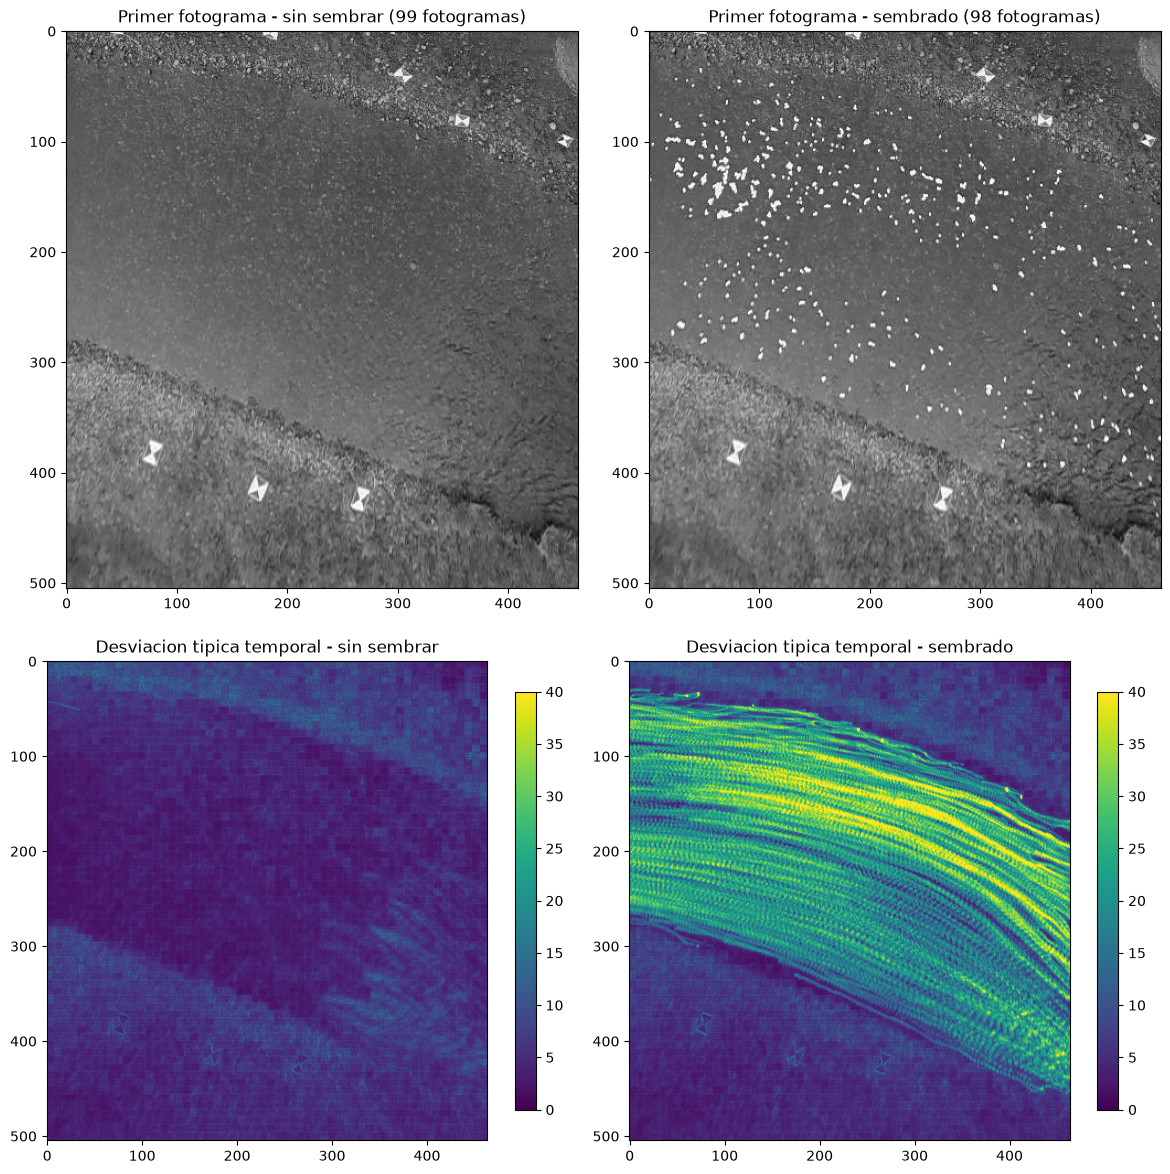

In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# OpenCV: los metadatos y el primer fotograma del video que se mide.
cap = cv2.VideoCapture(str(ARCHIVO_VIDEO))
FPS = cap.get(cv2.CAP_PROP_FPS)
N_TOTAL = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
ok, frame_bgr = cap.read()
cap.release()
DT = 1.0 / FPS                    # intervalo entre fotogramas: entra en la velocidad
# OpenCV lee en BGR; matplotlib espera RGB.
frame = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
ALTO_PX, ANCHO_PX = frame.shape[:2]                                                  # [v7]

# Forma (filas, columnas, canales): las filas son la altura y las columnas el ancho.
print(f"Dimensiones del fotograma: {frame.shape}")
print(f"FPS del video: {FPS:.4f}  ->  DT = {DT * 1000:.3f} ms")
print(f"Fotogramas en el video: {N_TOTAL}")


def cargar(ruta):
    """[v7] El video entero en gris (son ~100 fotogramas de 464x505: 23 MB)."""
    cap = cv2.VideoCapture(str(ruta))
    fs = []
    while True:
        ok, fr = cap.read()
        if not ok:
            break
        fs.append(cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY).astype(np.float32))
    cap.release()
    return np.stack(fs)


pilas = {etq: cargar(ruta) for etq, ruta in VIDEOS.items()}                          # [v7]
fig, axes = plt.subplots(2, 2, figsize=(12, 12))
for j, etq in enumerate(VIDEOS):
    axes[0, j].imshow(pilas[etq][0], cmap="gray")
    axes[0, j].set_title(f"Primer fotograma - {etq} ({len(pilas[etq])} fotogramas)")
    im = axes[1, j].imshow(pilas[etq].std(axis=0), cmap="viridis", vmin=0, vmax=40)
    axes[1, j].set_title(f"Desviacion tipica temporal - {etq}")
    plt.colorbar(im, ax=axes[1, j], shrink=0.75)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig1_fotograma.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 2 - Geometria: escala dada y cinco secciones

La escala la declara el `Readme.txt`: **0.0174 m/px**, video ya ortorrectificado. Las 5 secciones
de aforo (XS1 a XS5, 49 verticales) vienen con la posicion de cada vertical en pixeles: es
geometria, como las progresivas del CSV de la v3; las velocidades no se tocan hasta la Parte 7.

**La direccion del flujo, una por seccion.** El rio gira dentro del encuadre: correlando parches
entre fotogramas del video sembrado la direccion va de +6 a +39 grados. No se barren angulos (seria
ajustar contra los datos): se usa la **normal a cada seccion**, porque un aforador traza sus secciones
perpendiculares a la corriente. Sale de los extremos de cada seccion, sin mirar ninguna velocidad.

In [3]:
import pandas as pd

# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Geometria                                                       [v7]
# ---------------------------------------------------------------------------------------
# Escala de la imagen ortorrectificada, declarada por el Readme.txt.  (obtenido del dataset)
ESCALA = 0.0174               # m/px
# Margen al borde del fotograma: una muestra mas cerca toma valores de borde, no del agua.
MARGEN_BORDE = 5              # px
# ---------------------------------------------------------------------------------------

# [v7] Las verticales de las 5 secciones: SOLO las posiciones (la tercera columna, la
# velocidad, no se lee aqui).  (obtenido del dataset)
_val = pd.read_excel(ARCHIVO_VALIDACION, header=None)
_filas, _seccion = [], None
for _, r in _val.iloc[11:].iterrows():
    etiqueta = str(r[0])
    if etiqueta.startswith("XS"):
        _seccion = etiqueta
    elif _seccion is not None and etiqueta.replace(".", "").isdigit():
        _filas.append((_seccion, float(r[0]), float(r[1])))
verticales = pd.DataFrame(_filas, columns=["seccion", "x", "y"])
SECCIONES = list(dict.fromkeys(verticales.seccion))
N_ESTACIONES = len(verticales)
MAPA_RECT = None              # el video ya esta en el plano del agua

# [v7] La direccion del flujo de cada seccion es su normal.
angulos = {}
for sec in SECCIONES:
    p = verticales[verticales.seccion == sec][["x", "y"]].to_numpy()
    d = p[-1] - p[0]
    angulos[sec] = float(np.degrees(np.arctan2(-d[0], d[1])))
verticales["angulo"] = verticales.seccion.map(angulos)
# Progresiva de cada vertical a lo largo de su propia seccion, desde el primer punto.
verticales["s_m"] = [np.hypot(r.x - verticales[verticales.seccion == r.seccion].x.iloc[0],
                              r.y - verticales[verticales.seccion == r.seccion].y.iloc[0]) * ESCALA
                     for r in verticales.itertuples()]
print(f"Escala declarada: {ESCALA * 1000:.1f} mm/px; {len(SECCIONES)} secciones, "
      f"{N_ESTACIONES} verticales")
for sec in SECCIONES:
    print(f"  {sec}: {int((verticales.seccion == sec).sum())} verticales, normal "
          f"{angulos[sec]:+.1f} grados")

Escala declarada: 17.4 mm/px; 5 secciones, 49 verticales
  XS1: 9 verticales, normal +8.2 grados
  XS2: 10 verticales, normal +13.3 grados
  XS3: 10 verticales, normal +16.0 grados
  XS4: 10 verticales, normal +13.9 grados
  XS5: 10 verticales, normal +12.8 grados


---
## Parte 3 - Lineas de busqueda

Como en la v6, una **banda** de lineas por estacion, pero estrecha: **6 px y 3 lineas**, porque las
verticales de una seccion estan a solo ~25 px (6 px son un 24 %, la misma proporcion que en la v6).
Cada banda va girada a la normal de su seccion.

Las lineas miden 4.2 m (240 px) y el encuadre solo 464x505: las de XS1 y XS5 se salen. En lugar de
descartarlas, se marca **que muestras caen dentro del fotograma**: `medir_sti` solo usa los bloques
de la STI que no tocan ninguna muestra de fuera. La **cobertura** de cada estacion es la fraccion de
su linea que se ve.

Desplazamiento esperado: 5.17 px/fotograma -> DS = 5 px, sigma antialias = 2.5 px, estelas a 46.0 grados
49 estaciones x 3 lineas de 48 muestras (4.18 m cada una)
Cobertura por seccion: {'XS1': 0.52, 'XS2': 0.96, 'XS3': 1.0, 'XS4': 0.94, 'XS5': 0.58}


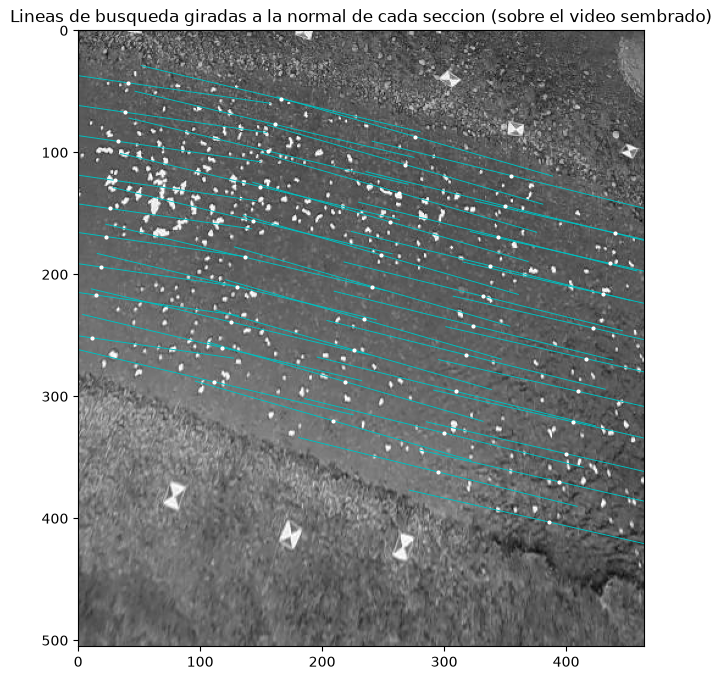

In [4]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Lineas de busqueda
# ---------------------------------------------------------------------------------------
# Orden de magnitud de la velocidad superficial: el centro del rango que da la correlacion de
# parches entre fotogramas consecutivos del video sembrado (4.0 a 6.4 px/fotograma). Para el
# video sin sembrar no se puede medir (no hay con que): se usa el mismo, como todo lo demas.
V_ESPERADA = 0.45             # m/s   [v7]
# [v7] Lineas de 48 muestras (4.2 m): mas largas se saldrian del fotograma en mas secciones.
# Banda estrecha: las verticales de una seccion estan a ~25 px.
LARGO_LINEA = 48 * 5 * ESCALA    # m
ANCHO_BANDA, PASO_BANDA = 6, 3   # px
# ---------------------------------------------------------------------------------------

centros = verticales[["x", "y"]].to_numpy()                                           # [v7]
D_ESPERADO = V_ESPERADA * DT / ESCALA        # px por fotograma
DS = int(round(D_ESPERADO))                  # paso de muestreo: estelas a ~45 grados
SIGMA_ANTIALIAS = 0.5 * DS                   # filtro paso bajo obligatorio antes de submuestrear
print(f"Desplazamiento esperado: {D_ESPERADO:.2f} px/fotograma -> DS = {DS} px, "
      f"sigma antialias = {SIGMA_ANTIALIAS:.1f} px, estelas a "
      f"{np.degrees(np.arctan(D_ESPERADO / DS)):.1f} grados")


def mapa_lineas(centros, angulos_deg, ds, largo):
    """Coordenadas de muestreo de cada linea: mapx, mapy de forma (n_lineas, n_muestras).

    Cada linea tiene su centro (x, y) y su largo en px.
    """
    centros = np.atleast_2d(np.asarray(centros, float))
    angs = np.radians(np.broadcast_to(np.asarray(angulos_deg, float), (len(centros),)))
    n_mu = int(largo / ds)
    # t recorre la linea centrada en su punto medio, en pixeles
    t = (np.arange(n_mu) - (n_mu - 1) / 2) * ds
    mapx = np.zeros((len(centros), n_mu), np.float32)
    mapy = np.zeros((len(centros), n_mu), np.float32)
    for i, ((cx, cy), a) in enumerate(zip(centros, angs)):
        mapx[i] = cx + t * np.cos(a)
        mapy[i] = cy + t * np.sin(a)
    return mapx, mapy


def mapa_banda(centros, angulos_deg, ds, largo, ancho, paso):
    """Una banda de lineas paralelas por estacion: (n_est * n_banda, n_muestras).

    [v7] Un angulo por estacion (o uno para todas).
    """
    c = np.asarray(centros, float)
    a = np.radians(np.broadcast_to(np.asarray(angulos_deg, float), (len(c),)))
    perp = np.column_stack([-np.sin(a), np.cos(a)])   # a traves de la linea, por estacion
    offsets = np.arange(-ancho / 2, ancho / 2 + 1e-9, paso)
    todos = (c[:, None, :] + offsets[None, :, None] * perp[:, None, :]).reshape(-1, 2)
    angs = np.repeat(np.degrees(a), len(offsets))
    return (*mapa_lineas(todos, angs, ds, largo), len(offsets))


mapx, mapy, N_BANDA = mapa_banda(centros, verticales.angulo.to_numpy(), DS, LARGO_LINEA / ESCALA,
                                 ANCHO_BANDA, PASO_BANDA)                          # [v7]
# [v7] Que muestras caen dentro del fotograma, en todas las lineas de la banda.
dentro = ((mapx >= MARGEN_BORDE) & (mapx < ANCHO_PX - MARGEN_BORDE)
          & (mapy >= MARGEN_BORDE) & (mapy < ALTO_PX - MARGEN_BORDE))
VALIDO = dentro.reshape(N_ESTACIONES, N_BANDA, -1).all(axis=1)
verticales["cobertura"] = VALIDO.mean(axis=1)
print(f"{N_ESTACIONES} estaciones x {N_BANDA} lineas de {mapx.shape[1]} muestras "
      f"({mapx.shape[1] * DS * ESCALA:.2f} m cada una)")
print("Cobertura por seccion:", verticales.groupby("seccion").cobertura.min().round(2).to_dict())

plt.figure(figsize=(8, 8))
plt.imshow(pilas["sembrado"][0], cmap="gray")                                        # [v7]
for i in range(N_ESTACIONES):
    lin = slice(i * N_BANDA, (i + 1) * N_BANDA)
    plt.plot(mapx[lin][N_BANDA // 2], mapy[lin][N_BANDA // 2],
             "c-" if verticales.cobertura[i] >= 0.5 else "r-", lw=0.7)
plt.plot(verticales.x, verticales.y, "w.", ms=4)
plt.xlim(0, ANCHO_PX); plt.ylim(ALTO_PX, 0)
plt.title("Lineas de busqueda giradas a la normal de cada seccion (sobre el video sembrado)")
plt.savefig(DIR_SALIDA / "fig2_lineas_busqueda.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 4 - Velocidades superficiales con STIV

El proceso de la v6, ahora dentro de una funcion, `medir_video`, que se llama una vez por video con
la misma configuracion. Dos cambios en el estimador, los dos por el tamano de este video:

- **`LADO_BLOQUE` = 24.** 99 fotogramas y lineas de 48 muestras: un bloque de 64 no cabe, y con 32
  quedan solo 2 bloques a lo largo de la linea. Con 24 caben 3 x 7 = 21.
- **`medir_sti` salta los bloques que tocan muestras fuera del fotograma** (argumento `valido`).

In [5]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Cuanto video se procesa y parametros del estimador
# ---------------------------------------------------------------------------------------
# El video entero (los dos tienen menos de 600 fotogramas).
N_FRAMES = 600
# [v7] Lado del bloque de STI: 24, porque solo hay 99 fotogramas y 48 muestras por linea.
LADO_BLOQUE = 24
# Coherencia minima para que un bloque entre en la mediana ponderada.
COH_MIN_BLOQUE = 0.50
# Suavizado gaussiano previo a las derivadas, en pixeles de STI.
SIGMA_DERIVADA = 1.5
# ---------------------------------------------------------------------------------------


def construir_sti(archivo, mapx, mapy, n_frames, sigma, mapa_rect=None):
    """Apila n_frames filas muestreadas -> STI de forma (n_lineas, n_frames, n_muestras).

    Si se da un mapa de rectificacion (mapx, mapy del plano a la imagen), cada fotograma se
    rectifica con remap antes del antialias.
    """
    cap = cv2.VideoCapture(str(archivo))
    sti = np.zeros((mapx.shape[0], n_frames, mapx.shape[1]), np.float32)
    for k in range(n_frames):
        ok, fr = cap.read()
        if not ok:
            sti = sti[:, :k, :]
            break
        gris = cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY).astype(np.float32)
        if mapa_rect is not None:
            gris = cv2.remap(gris, mapa_rect[0], mapa_rect[1], cv2.INTER_LINEAR)
        # Antialias ANTES de muestrear: sin esto el submuestreo inventa orientaciones.
        gris = cv2.GaussianBlur(gris, (0, 0), sigma)
        sti[:, k, :] = cv2.remap(gris, mapx, mapy, cv2.INTER_LINEAR)
    cap.release()
    return sti


def preparar_sti(sti):
    """Quita el fondo estatico y el parpadeo global, y normaliza."""
    a = sti - sti.mean(axis=0, keepdims=True)   # fondo fijo de cada muestra (rayas verticales)
    a = a - a.mean(axis=1, keepdims=True)       # parpadeo de cada fotograma (rayas horizontales)
    d = a.std()
    return a / d if d > 0 else a


def tensor_estructura(bloque, sigma=SIGMA_DERIVADA):
    """Pendiente m (muestras/fotograma) y coherencia C de un trozo de STI."""
    # Gaussiana opcional y diferencias centrales.
    g = cv2.GaussianBlur(bloque, (0, 0), sigma) if sigma > 0 else bloque
    # eje 0 = tiempo (filas), eje 1 = espacio (columnas)
    It, Ix = np.gradient(g)
    Jxx = float((Ix * Ix).sum())
    Jtt = float((It * It).sum())
    Jxt = float((Ix * It).sum())
    if Jxx + Jtt <= 0:
        return np.nan, 0.0
    # autovector del autovalor MENOR = direccion a lo largo de las estelas
    _, vec = np.linalg.eigh(np.array([[Jxx, Jxt], [Jxt, Jtt]]))
    ex, et = vec[:, 0]
    if et < 0:            # el autovector esta definido salvo signo: se orienta hacia t creciente
        ex, et = -ex, -et
    m = ex / et if et != 0 else np.nan
    coherencia = np.sqrt((Jxx - Jtt) ** 2 + 4 * Jxt ** 2) / (Jxx + Jtt)
    return m, float(coherencia)


def medir_sti(sti_p, lado=LADO_BLOQUE, coh_min=COH_MIN_BLOQUE, sigma=SIGMA_DERIVADA, valido=None):
    """Pendiente robusta de una STI, por bloques con solape: (m, coherencia mediana).

    [v7] `valido` (una por muestra) marca las muestras dentro del fotograma; los bloques que
    tocan alguna de fuera no cuentan.
    """
    nt, nx = sti_p.shape
    paso = lado // 2
    ms, cs = [], []
    for t0 in range(0, nt - lado + 1, paso):
        for x0 in range(0, nx - lado + 1, paso):
            if valido is not None and not valido[x0:x0 + lado].all():               # [v7]
                continue
            m, c = tensor_estructura(sti_p[t0:t0 + lado, x0:x0 + lado], sigma)
            if np.isfinite(m):
                ms.append(m); cs.append(c)
    if not ms:
        return np.nan, 0.0
    ms, cs = np.array(ms), np.array(cs)
    coh_mediana = float(np.median(cs))
    usables = cs >= coh_min
    if usables.sum() == 0:
        return np.nan, coh_mediana
    # mediana ponderada por coherencia: los bloques nitidos pesan mas
    mm, cc = ms[usables], cs[usables]
    orden = np.argsort(mm)
    mm, cc = mm[orden], cc[orden]
    acumulado = np.cumsum(cc) / cc.sum()
    return float(mm[np.searchsorted(acumulado, 0.5)]), coh_mediana


def medir_video(archivo):
    """[v7] Lo que en la v6 era el cuerpo de esta celda, para un video cualquiera."""
    sti_crudo = construir_sti(archivo, mapx, mapy, N_FRAMES, SIGMA_ANTIALIAS, MAPA_RECT)
    # (estacion, linea de la banda, tiempo, muestra)
    sti_crudo = sti_crudo.reshape(N_ESTACIONES, N_BANDA, *sti_crudo.shape[1:])
    # Contraste temporal y brillo medio de cada estacion, antes de normalizar.
    contraste = np.median(sti_crudo.std(axis=2), axis=2).mean(axis=1)
    brillo = sti_crudo.mean(axis=(1, 2, 3))
    # Cada linea de la banda se normaliza por separado y luego se promedian.
    sti_prep = np.stack([np.mean([preparar_sti(l) for l in banda], axis=0) for banda in sti_crudo])
    v_stiv = np.full(N_ESTACIONES, np.nan)
    coherencia = np.full(N_ESTACIONES, np.nan)
    for i in range(N_ESTACIONES):
        m, coherencia[i] = medir_sti(sti_prep[i], valido=VALIDO[i])
        # [v7] modulo: la normal de cada seccion tiene un sentido arbitrario
        v_stiv[i] = abs(m) * DS * ESCALA / DT if np.isfinite(m) else np.nan
    return dict(sti_prep=sti_prep, contraste=contraste, brillo=brillo, v_stiv=v_stiv,
                coherencia=coherencia, n_frames=sti_crudo.shape[2])


resultados = {}
for etq, ruta in VIDEOS.items():                                                     # [v7]
    with benchmark.medir(f"Parte 4: STI y tensor [{etq}]", n_frames=len(pilas[etq])):
        resultados[etq] = medir_video(ruta)
    r = resultados[etq]
    print(f"[{etq:11s}] {r['n_frames']} fotogramas: coherencia mediana "
          f"{np.median(r['coherencia']):.3f}, maxima {r['coherencia'].max():.3f}; contraste "
          f"temporal mediano {np.median(r['contraste']):.2f}")

  [bench] Parte 4: STI y tensor [sin sembrar]: 0.5 s | CPU 0.5 s (1.1 nucleos) | RAM pico 360 MB
[sin sembrar] 99 fotogramas: coherencia mediana 0.196, maxima 0.559; contraste temporal mediano 0.79


  [bench] Parte 4: STI y tensor [sembrado]: 0.5 s | CPU 0.6 s (1.1 nucleos) | RAM pico 361 MB
[sembrado   ] 98 fotogramas: coherencia mediana 0.817, maxima 0.945; contraste temporal mediano 6.71


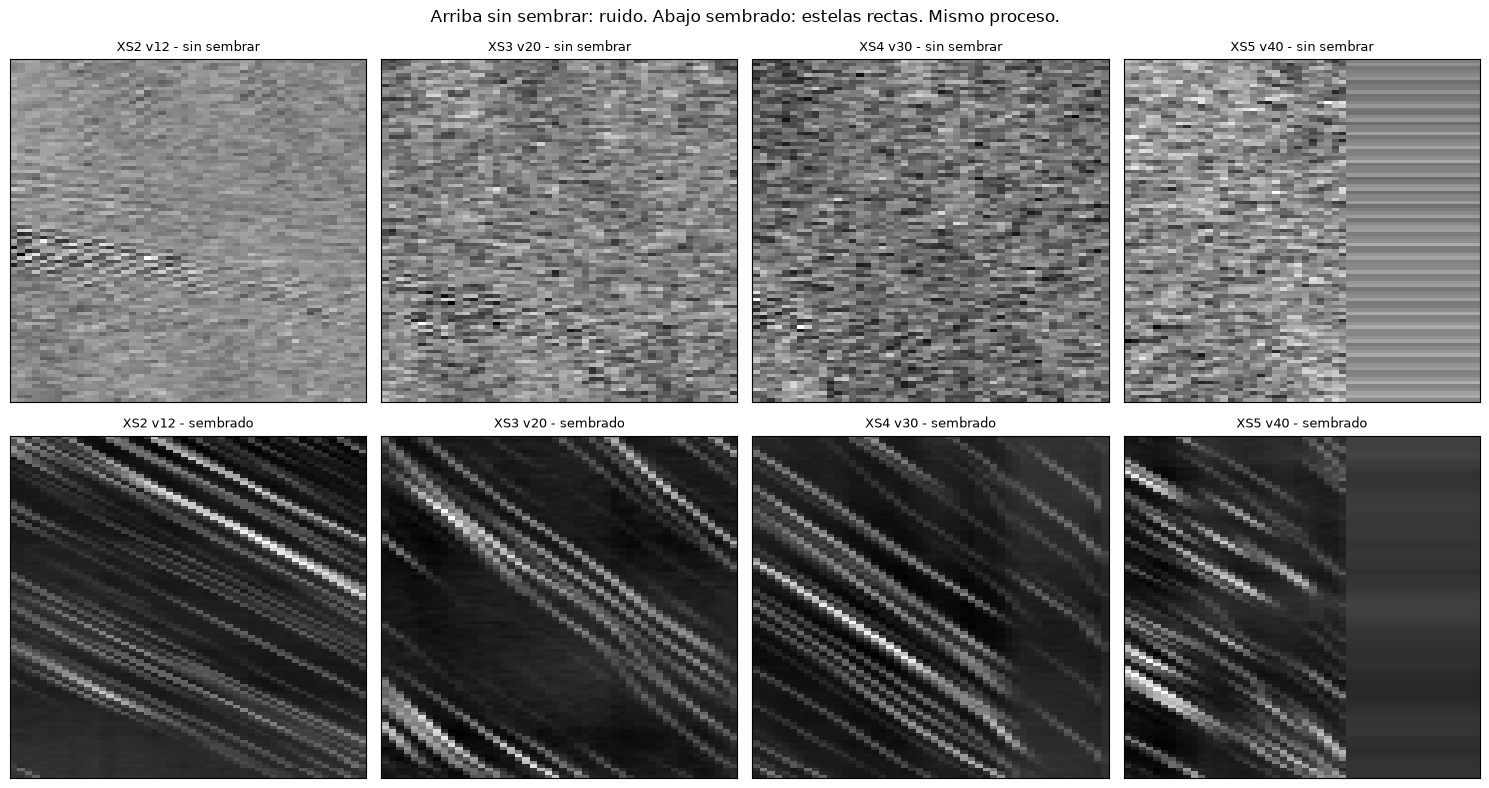

In [6]:
# [v7] Las mismas cuatro estaciones en los dos videos, con exactamente el mismo proceso.
DEMO = [12, 20, 30, 40]
fig, axes = plt.subplots(2, len(DEMO), figsize=(15, 8))
for fila, etq in enumerate(VIDEOS):
    for col, i in enumerate(DEMO):
        axes[fila, col].imshow(resultados[etq]["sti_prep"][i], cmap="gray", aspect="auto")
        axes[fila, col].set_title(f"{verticales.seccion[i]} v{i} - {etq}", fontsize=9)
        axes[fila, col].set_xticks([]); axes[fila, col].set_yticks([])
fig.suptitle("Arriba sin sembrar: ruido. Abajo sembrado: estelas rectas. Mismo proceso.")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig3_sti_comparadas.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 4b - Control de calidad

Los criterios heredados, **fijados de antemano y sin mirar estos datos**: que rechacen o no el video
sin sembrar solo significa algo si los umbrales no se eligieron para ello.

- **Coherencia >= 0.70**, la de la v3 a la v6.
- **Contraste temporal**: sigue desactivado desde la v6. Se calcula y se muestra.
- **Brillo**: el de la v6 (agua negra) no tiene sentido aqui, donde el agua tiene un brillo medio de
  ~100; se desactiva.
- **Cobertura >= 0.50**: una estacion que ve menos de la mitad de su linea no da bloques suficientes.

**No se rellena**: no hay batimetria y no hay caudal.

  [bench] Parte 4b: control de calidad: 0.0 s | CPU 0.0 s (0.0 nucleos) | RAM pico 362 MB
video            aceptadas   coh mediana   coh maxima   contraste mediano
sin sembrar        0/49            0.196        0.559                0.79
sembrado          38/49            0.817        0.945                6.71
La coherencia MAXIMA del video sin sembrar (0.559) no llega al umbral de 0.7.
El contraste temporal, aunque desactivado, separa tambien los dos videos sin solape: 1.50 como maximo sin sembrar, 2.64 como minimo sembrado.


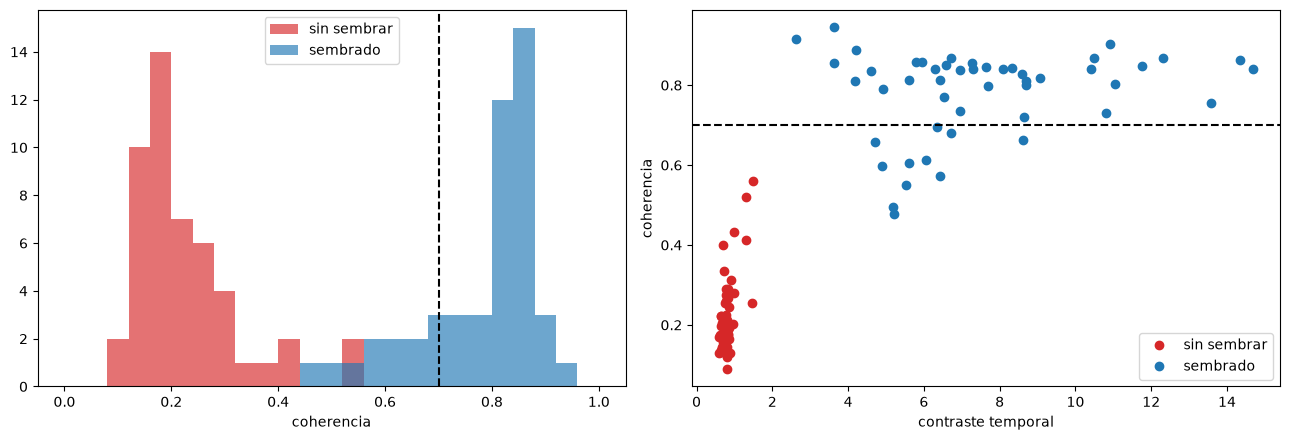

In [7]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Criterios de aceptacion
# ---------------------------------------------------------------------------------------
# Coherencia mediana minima para dar por buena una estacion. La misma de la v3 a la v6.
COH_MIN_ESTACION = 0.70
# Desactivado desde la v6.
CONTRASTE_MIN = 0.0
# [v7] Desactivado: el agua del Arrow no es negra.
BRILLO_MAX_AGUA = 255.0
# [v7] Fraccion minima de la linea dentro del fotograma.
COBERTURA_MIN = 0.50
# ---------------------------------------------------------------------------------------

medida, v_eff = {}, {}
with benchmark.medir("Parte 4b: control de calidad"):
    for etq, r in resultados.items():                                                # [v7]
        es_estatica = r["contraste"] < CONTRASTE_MIN
        es_orilla = r["brillo"] > BRILLO_MAX_AGUA
        fuera = verticales.cobertura.to_numpy() < COBERTURA_MIN                       # [v7]
        medida[etq] = ((~es_estatica) & (~es_orilla) & (~fuera)
                       & (r["coherencia"] >= COH_MIN_ESTACION) & np.isfinite(r["v_stiv"]))
        v_eff[etq] = np.where(medida[etq], r["v_stiv"], np.nan)

print("=" * 74)
print(f"{'video':<14}{'aceptadas':>12}{'coh mediana':>14}{'coh maxima':>13}{'contraste mediano':>20}")
for etq, r in resultados.items():
    print(f"{etq:<14}{medida[etq].sum():>6}/{N_ESTACIONES:<5}{np.median(r['coherencia']):>14.3f}"
          f"{r['coherencia'].max():>13.3f}{np.median(r['contraste']):>20.2f}")
print("=" * 74)
print(f"La coherencia MAXIMA del video sin sembrar ({resultados['sin sembrar']['coherencia'].max():.3f})"
      f" no llega al umbral de {COH_MIN_ESTACION}.")
print("El contraste temporal, aunque desactivado, separa tambien los dos videos sin solape: "
      f"{resultados['sin sembrar']['contraste'].max():.2f} como maximo sin sembrar, "
      f"{resultados['sembrado']['contraste'].min():.2f} como minimo sembrado.")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for etq, color in zip(VIDEOS, ["tab:red", "tab:blue"]):
    ax[0].hist(resultados[etq]["coherencia"], bins=np.linspace(0, 1, 26), alpha=0.65, color=color, label=etq)
    ax[1].plot(resultados[etq]["contraste"], resultados[etq]["coherencia"], "o", color=color, label=etq)
ax[0].axvline(COH_MIN_ESTACION, color="k", ls="--"); ax[0].set_xlabel("coherencia"); ax[0].legend()
ax[1].axhline(COH_MIN_ESTACION, color="k", ls="--"); ax[1].set_xlabel("contraste temporal")
ax[1].set_ylabel("coherencia"); ax[1].legend()
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig4_control_calidad.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 4c - Por que el video sin sembrar no se puede medir

Que **esta** configuracion no encuentre nada no prueba que no haya nada. El caso original
(`casos/07_arrow_siembra`) probo nueve variantes de rescate (muestreo hasta `DS` = 1, bandas de hasta
60 px, paso alto espacial, una STI por seccion entera) y ninguna dio una sola estacion. Aqui se
reproduce la medida que explica por que: la **curva de decorrelacion**, cuanto sobrevive el dibujo de
la superficie al pasar el tiempo.

Se correlan parches del mismo sitio separados por un salto temporal creciente y se toma el pico: el
desplazamiento no penaliza (el pico se busca en toda la ventana), asi que lo unico que baja la curva
es que el patron **deje de existir**. No depende del algoritmo que se use despues, y no usa la
referencia del aforo.

  [bench] Parte 4c: curvas de decorrelacion: 2.3 s | CPU 2.2 s (1.0 nucleos) | RAM pico 522 MB
 salto_s  sin sembrar  sembrado
     0.2        0.055     0.725
     0.4        0.072     0.559
     0.6        0.054     0.428
     0.8        0.042     0.337
     1.2        0.035     0.215
     1.6        0.031     0.154


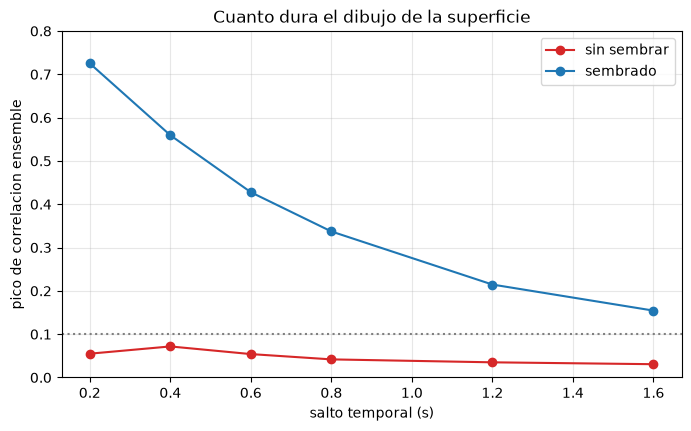

In [8]:
# [v7] Celda nueva, propia del experimento.
def curva_decorrelacion(pila, saltos, parches, radio=28):
    """Pico de correlacion ensemble frente al salto temporal."""
    nrm = (pila - pila.mean(axis=0)) / (pila.std(axis=0) + 1e-6)
    curva = []
    for dt in saltos:
        busq = min(10 + 7 * dt, 60)
        picos = []
        for (x0, y0) in parches:
            acc = None
            for k in range(len(nrm) - dt):
                A = nrm[k, y0:y0 + 2 * radio, x0:x0 + 2 * radio]
                B = nrm[k + dt, max(y0 - busq, 0):y0 + 2 * radio + busq,
                        max(x0 - busq, 0):x0 + 2 * radio + busq]
                r = cv2.matchTemplate(B, A, cv2.TM_CCOEFF_NORMED)
                acc = r if acc is None else acc + r
            picos.append(float((acc / (len(nrm) - dt)).max()))
        curva.append(float(np.mean(picos)))
    return np.array(curva)


SALTOS = [1, 2, 3, 4, 6, 8]
PARCHES = [(150, 150), (250, 200), (200, 250)]     # parches de agua, lejos de las orillas
with benchmark.medir("Parte 4c: curvas de decorrelacion"):
    decorr = {etq: curva_decorrelacion(pilas[etq], SALTOS, PARCHES) for etq in VIDEOS}
tabla_decorr = pd.DataFrame({"salto_s": np.array(SALTOS) * DT,
                             **{etq: np.round(decorr[etq], 3) for etq in VIDEOS}})
tabla_decorr.to_csv(DIR_SALIDA / "decorrelacion.csv", index=False)
print(tabla_decorr.to_string(index=False))

plt.figure(figsize=(8, 4.5))
for etq, color in zip(VIDEOS, ["tab:red", "tab:blue"]):
    plt.plot(np.array(SALTOS) * DT, decorr[etq], "o-", color=color, label=etq)
plt.axhline(0.1, color="gray", ls=":")
plt.xlabel("salto temporal (s)"); plt.ylabel("pico de correlacion ensemble")
plt.title("Cuanto dura el dibujo de la superficie"); plt.ylim(0, 0.8); plt.legend(); plt.grid(alpha=0.3)
plt.savefig(DIR_SALIDA / "fig5_decorrelacion.png", dpi=110, bbox_inches="tight")
plt.show()

El sembrado decae despacio (0.7 a 0.2 s, todavia 0.15 a 1.6 s): sobra margen para seguirlo. El
video sin sembrar esta en nivel de ruido **ya en el salto mas corto que el registro permite** y su
curva es plana: no hay patron que perder en ningun par de fotogramas. Ninguna configuracion de STIV,
ni de PIV, ni de flujo optico lo arregla; lo arreglaria sembrar o grabar mas deprisa, que es la
adquisicion, no el codigo.

---
## Parte 5 - Perfiles transversales

Sin batimetria no hay caudal. Del video sin sembrar no hay perfil que dibujar: ese es el resultado.

  [bench] Parte 5: perfiles transversales: 0.0 s | CPU 0.0 s (0.0 nucleos) | RAM pico 369 MB
[sin sembrar]  0 estaciones, mediana nan m/s
[sembrado   ] 38 estaciones, mediana 0.3978 m/s


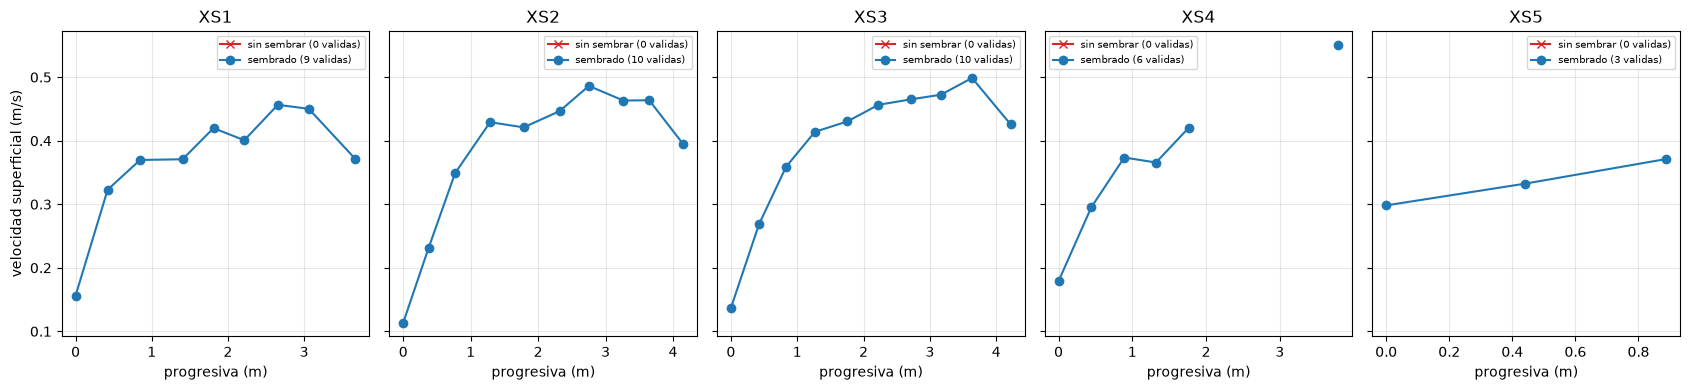

In [9]:
with benchmark.medir("Parte 5: perfiles transversales"):
    v_mediana = {etq: float(np.nanmedian(v)) if np.isfinite(v).any() else np.nan
                 for etq, v in v_eff.items()}                                        # [v7]
for etq in VIDEOS:
    print(f"[{etq:11s}] {int(medida[etq].sum()):2d} estaciones, mediana {v_mediana[etq]:.4f} m/s")

perfil = verticales.copy()
for etq in VIDEOS:                                                                   # [v7]
    suf = etq.replace(" ", "_")
    perfil[f"coherencia_{suf}"] = resultados[etq]["coherencia"]
    perfil[f"contraste_{suf}"] = resultados[etq]["contraste"]
    perfil[f"v_{suf}"] = v_eff[etq]
perfil.to_csv(SALIDA_PERFIL, index=False)

import json
config = dict(videos={k: v.name for k, v in VIDEOS.items()}, fps=FPS, escala_m_px=ESCALA,
              angulos_seccion=angulos, v_esperada=V_ESPERADA, ds_px=DS,
              sigma_antialias=SIGMA_ANTIALIAS, largo_linea_m=LARGO_LINEA,
              ancho_banda_px=ANCHO_BANDA, paso_banda_px=PASO_BANDA, lado_bloque=LADO_BLOQUE,
              coh_min_bloque=COH_MIN_BLOQUE, sigma_derivada=SIGMA_DERIVADA,
              coh_min_estacion=COH_MIN_ESTACION, contraste_min=CONTRASTE_MIN,
              brillo_max_agua=BRILLO_MAX_AGUA, cobertura_min=COBERTURA_MIN,
              aceptadas={k: int(v.sum()) for k, v in medida.items()})
SALIDA_CONFIG.write_text(json.dumps(config, indent=2), encoding="utf-8")

fig, axes = plt.subplots(1, len(SECCIONES), figsize=(17, 4), sharey=True)
for ax, sec in zip(axes, SECCIONES):
    sel = (verticales.seccion == sec).to_numpy()
    for etq, color, marca in zip(VIDEOS, ["tab:red", "tab:blue"], ["x", "o"]):
        ax.plot(verticales.s_m[sel], v_eff[etq][sel], marca + "-", color=color,
                label=f"{etq} ({int(medida[etq][sel].sum())} validas)")
    ax.set_title(sec); ax.set_xlabel("progresiva (m)"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
axes[0].set_ylabel("velocidad superficial (m/s)")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig6_perfiles.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 6 - Recursos consumidos

El caso mas barato de la serie (99 fotogramas de 464x505). Las dos pasadas cuestan lo mismo: **el
coste no depende de que haya senal**, solo de cuantos pixeles hay que leer.

Maquina donde se han medido los tiempos:
  cpu_nucleos_fisicos: 12
  cpu_nucleos_logicos: 16
  ram_total_gb: 42.7
  ram_disponible_gb: 21.1

Tiempo total medido: 3.2 s
Pico de memoria del proceso: 522 MB


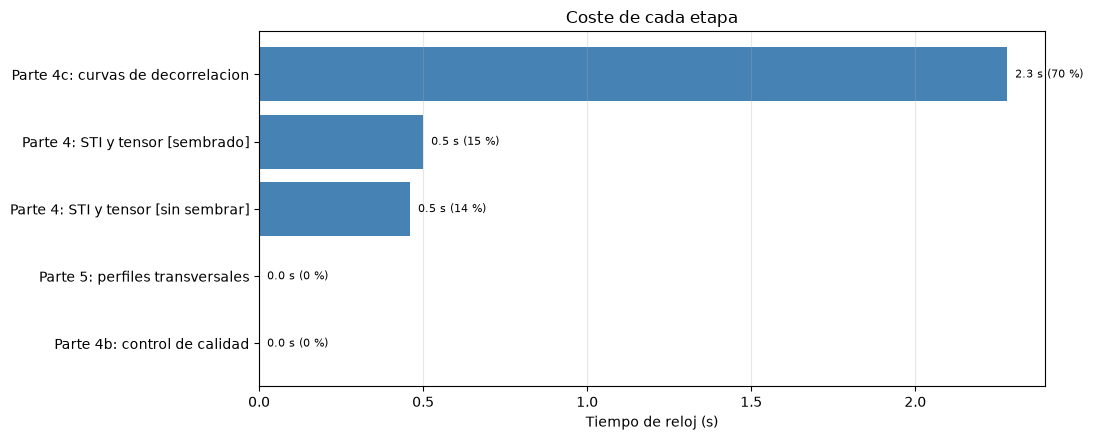

,etapa,segundos,cpu_s,nucleos,ram_pico_mb,ram_neta_mb,n_frames,pct_tiempo
0,Parte 4: STI y tensor [sin sembrar],0.46,0.50,1.08,359.6,-0.1,99.0,14.2
1,Parte 4: STI y tensor [sembrado],0.50,0.58,1.15,361.2,1.0,98.0,15.4
2,Parte 4b: control de calidad,0.00,0.00,0.00,362.2,0.0,NaN,0.0
3,Parte 4c: curvas de decorrelacion,2.28,2.25,0.99,521.8,2.6,NaN,70.4
4,Parte 5: perfiles transversales,0.00,0.00,0.00,368.6,0.0,NaN,0.0


In [10]:
print("Maquina donde se han medido los tiempos:")
for k, v in benchmark.entorno().items():
    print(f"  {k}: {v}")

tabla_recursos = benchmark.tabla()
tabla_recursos.to_csv(SALIDA_BENCHMARK, index=False)
print(f"\nTiempo total medido: {tabla_recursos['segundos'].sum():.1f} s")
print(f"Pico de memoria del proceso: {tabla_recursos['ram_pico_mb'].max():.0f} MB")

fig, ax = plt.subplots(figsize=(11, 4.5))
orden = tabla_recursos.sort_values("segundos")
ax.barh(orden["etapa"], orden["segundos"], color="steelblue")
ax.set_xlabel("Tiempo de reloj (s)")
ax.set_title("Coste de cada etapa")
ax.grid(axis="x", alpha=0.3)
for y, (seg, pct) in enumerate(zip(orden["segundos"], orden["pct_tiempo"])):
    ax.text(seg, y, f"  {seg:.1f} s ({pct:.0f} %)", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig7_recursos.png", dpi=110, bbox_inches="tight")
plt.show()
tabla_recursos

---
## Parte 7 - Comparacion con la referencia del dataset

Hasta aqui no se ha usado ni una sola velocidad de referencia. Hay dos preguntas distintas:

1. **El video sin sembrar frente a la referencia**: no hay nada que comparar, cero estaciones.
2. **El video sembrado frente a la referencia**: aqui si hay velocidades que enfrentar.

Y una tercera, nueva en esta version: si el perfil de STIV no se parece al de la referencia, **es el
metodo o es la imagen?** Para saberlo se mide el mismo video con un **PIV de correlacion ensemble**,
que no comparte con STIV ni el planteamiento ni una linea de codigo.

**Esta es la ultima parte del notebook. No se vuelve atras a ajustar nada.**

In [11]:
# [v7] Parte nueva.
# ---------------------------------------------------------------------------------------
#  Datos de validacion. Primera y unica vez que aparecen. (obtenido del dataset)
# ---------------------------------------------------------------------------------------
_vel, _sec = [], None
for _, r in _val.iloc[11:].iterrows():
    etiqueta = str(r[0])
    if etiqueta.startswith("XS"):
        _sec = etiqueta
    elif _sec is not None and etiqueta.replace(".", "").isdigit():
        _vel.append(float(r[2]))
V_REFERENCIA = np.array(_vel)
# ---------------------------------------------------------------------------------------

for etq in VIDEOS:
    ok = np.isfinite(v_eff[etq])
    if not ok.any():
        print(f"[{etq}] 0 estaciones de {N_ESTACIONES}: la referencia existe (media "
              f"{V_REFERENCIA.mean():.3f} m/s), habia agua corriendo; falta textura en la imagen.")
        continue
    d = v_eff[etq][ok] - V_REFERENCIA[ok]
    print(f"[{etq}] {ok.sum()} estaciones: media STIV {v_eff[etq][ok].mean():.4f} m/s, referencia "
          f"{V_REFERENCIA[ok].mean():.4f} m/s; sesgo {100 * d.mean() / V_REFERENCIA[ok].mean():+.1f} %, "
          f"RMSE {np.sqrt((d ** 2).mean()):.4f} m/s, r = {np.corrcoef(v_eff[etq][ok], V_REFERENCIA[ok])[0, 1]:+.3f}")

[sin sembrar] 0 estaciones de 49: la referencia existe (media 0.418 m/s), habia agua corriendo; falta textura en la imagen.
[sembrado] 38 estaciones: media STIV 0.3745 m/s, referencia 0.4166 m/s; sesgo -10.1 %, RMSE 0.1552 m/s, r = -0.037


  [bench] Parte 7: PIV ensemble (arbitro): 16.5 s | CPU 16.3 s (1.0 nucleos) | RAM pico 577 MB
  STIV frente a la referencia  (38 puntos): r = -0.037, RMSE = 0.1552 m/s
  PIV  frente a la referencia  (36 puntos): r = -0.009, RMSE = 0.1532 m/s
  STIV frente al PIV           (27 puntos): r = +0.975, RMSE = 0.0264 m/s


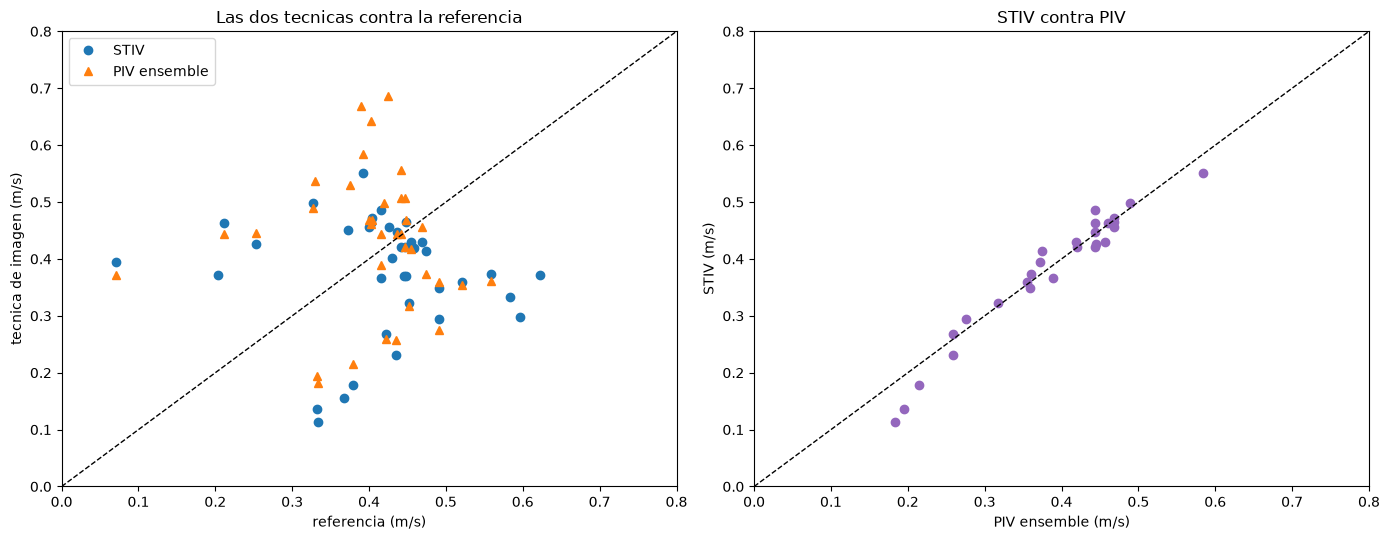

,concepto,valor,unidad
0,"Estaciones aceptadas, SIN SEMBRAR",0.000000,de 49
1,"Estaciones aceptadas, SEMBRADO",38.000000,de 49
2,"Coherencia maxima, sin sembrar",0.558961,umbral 0.7
3,"Velocidad mediana STIV, sembrado",0.397829,m/s
4,Correlacion STIV vs referencia,-0.037060,-
5,Correlacion STIV vs PIV,0.974729,-
6,Caudal,NaN,no calculable: el dataset no da batimetria


In [12]:
# [v7] PIV de correlacion ensemble: la correlacion de cada parche se promedia sobre todos los
# pares de fotogramas consecutivos antes de buscar el pico. Arbitro independiente de STIV.
RADIO_PARCHE, RADIO_BUSQUEDA, PASO_REJILLA = 20, 14, 20     # px


def piv_ensemble(pila, radio, busqueda, paso):
    """Campo de desplazamiento por correlacion ensemble. Devuelve X, Y, U, V, C."""
    nrm = (pila - pila.mean(axis=0)) / (pila.std(axis=0) + 1e-6)
    xs = np.arange(radio + busqueda, pila.shape[2] - radio - busqueda, paso)
    ys = np.arange(radio + busqueda, pila.shape[1] - radio - busqueda, paso)
    U = np.full((len(ys), len(xs)), np.nan)
    V, Cc = U.copy(), U.copy()
    for jj, y0 in enumerate(ys):
        for ii, x0 in enumerate(xs):
            acc = None
            for k in range(len(nrm) - 1):
                A = nrm[k, y0 - radio:y0 + radio, x0 - radio:x0 + radio]
                B = nrm[k + 1, y0 - radio - busqueda:y0 + radio + busqueda,
                        x0 - radio - busqueda:x0 + radio + busqueda]
                r = cv2.matchTemplate(B, A, cv2.TM_CCOEFF_NORMED)
                acc = r if acc is None else acc + r
            acc /= (len(nrm) - 1)
            j, i = np.unravel_index(acc.argmax(), acc.shape)
            U[jj, ii], V[jj, ii], Cc[jj, ii] = i - busqueda, j - busqueda, acc.max()
    X, Y = np.meshgrid(xs, ys)
    return X, Y, U, V, Cc


from scipy.interpolate import griddata

with benchmark.medir("Parte 7: PIV ensemble (arbitro)", n_frames=len(pilas["sembrado"])):
    Xg, Yg, Ug, Vg, Cg = piv_ensemble(pilas["sembrado"], RADIO_PARCHE, RADIO_BUSQUEDA, PASO_REJILLA)
vel_piv = np.where(Cg > 0.25, np.hypot(Ug, Vg) * ESCALA / DT, np.nan)
fin = np.isfinite(vel_piv.ravel())
v_piv = griddata(np.column_stack([Xg.ravel(), Yg.ravel()])[fin], vel_piv.ravel()[fin],
                 verticales[["x", "y"]].to_numpy(), method="linear")

v_sem = v_eff["sembrado"]
def estad(a, b):
    ok = np.isfinite(a) & np.isfinite(b)
    return ok.sum(), np.corrcoef(a[ok], b[ok])[0, 1], np.sqrt(((a[ok] - b[ok]) ** 2).mean())
print("=" * 70)
for nombre, a, b in [("STIV frente a la referencia", v_sem, V_REFERENCIA),
                     ("PIV  frente a la referencia", v_piv, V_REFERENCIA),
                     ("STIV frente al PIV", v_sem, v_piv)]:
    n_, r_, e_ = estad(a, b)
    print(f"  {nombre:28s} ({n_:2d} puntos): r = {r_:+.3f}, RMSE = {e_:.4f} m/s")
print("=" * 70)

comparacion = verticales[["seccion", "x", "y", "s_m"]].copy()
comparacion["v_ref"] = V_REFERENCIA
comparacion["v_stiv_sembrado"] = v_sem
comparacion["v_piv_sembrado"] = v_piv
comparacion.to_csv(DIR_SALIDA / "comparacion_referencia.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
lim = [0.0, 0.8]
ax[0].plot(V_REFERENCIA, v_sem, "o", label="STIV"); ax[0].plot(V_REFERENCIA, v_piv, "^", label="PIV ensemble")
ax[0].plot(lim, lim, "k--", lw=1); ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel("referencia (m/s)"); ax[0].set_ylabel("tecnica de imagen (m/s)"); ax[0].legend()
ax[0].set_title("Las dos tecnicas contra la referencia")
ax[1].plot(v_piv, v_sem, "o", color="tab:purple"); ax[1].plot(lim, lim, "k--", lw=1)
ax[1].set_xlim(lim); ax[1].set_ylim(lim); ax[1].set_xlabel("PIV ensemble (m/s)"); ax[1].set_ylabel("STIV (m/s)")
ax[1].set_title("STIV contra PIV")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig8_arbitro_independiente.png", dpi=110, bbox_inches="tight")
plt.show()

n_s, r_s, e_s = estad(v_sem, V_REFERENCIA)
resumen = pd.DataFrame([
    dict(concepto="Estaciones aceptadas, SIN SEMBRAR", valor=int(medida["sin sembrar"].sum()), unidad=f"de {N_ESTACIONES}"),
    dict(concepto="Estaciones aceptadas, SEMBRADO", valor=int(medida["sembrado"].sum()), unidad=f"de {N_ESTACIONES}"),
    dict(concepto="Coherencia maxima, sin sembrar", valor=float(resultados["sin sembrar"]["coherencia"].max()), unidad=f"umbral {COH_MIN_ESTACION}"),
    dict(concepto="Velocidad mediana STIV, sembrado", valor=v_mediana["sembrado"], unidad="m/s"),
    dict(concepto="Correlacion STIV vs referencia", valor=r_s, unidad="-"),
    dict(concepto="Correlacion STIV vs PIV", valor=estad(v_sem, v_piv)[1], unidad="-"),
    dict(concepto="Caudal", valor=np.nan, unidad="no calculable: el dataset no da batimetria"),
])
resumen.to_csv(SALIDA_RESUMEN, index=False)
resumen

---
## Archivos generados

Todo queda en `salidas/`, sin tocar los datos de entrada.

In [13]:
print(f"Contenido de {DIR_SALIDA}:\n")
for archivo in sorted(DIR_SALIDA.iterdir()):
    # st_size da el tamano en bytes; se divide entre 1024 para mostrarlo en KiB.
    print(f"  {archivo.name:<34} {archivo.stat().st_size / 1024:>10.1f} KiB")

Contenido de salidas:

  benchmark_recursos.csv                    0.4 KiB
  comparacion_referencia.csv                3.4 KiB
  config.json                               0.7 KiB
  decorrelacion.csv                         0.2 KiB
  fig1_fotograma.png                     1551.9 KiB
  fig2_lineas_busqueda.png                479.5 KiB
  fig3_sti_comparadas.png                 134.4 KiB
  fig4_control_calidad.png                 38.3 KiB
  fig5_decorrelacion.png                   40.5 KiB
  fig6_perfiles.png                        74.3 KiB
  fig7_recursos.png                        28.9 KiB
  fig8_arbitro_independiente.png           71.9 KiB
  perfil_velocidades.csv                    6.7 KiB
  resumen.csv                               0.4 KiB


---
## Lectura del resultado

1. **El video sin sembrar no es medible**, y no por el codigo: la curva de decorrelacion esta en nivel
   de ruido en el primer salto. Ningun umbral se ajusto para llegar ahi.
2. **El sembrado lo cambia todo, y es lo unico que cambia**: mismo rio, camara, encuadre, escala y
   configuracion, hasta la ultima constante.
3. **Sobre el video sembrado, STIV y el PIV ensemble coinciden entre si mucho mas que cualquiera de
   los dos con la referencia.** Dos tecnicas sin una linea de codigo en comun que discrepan igual de
   un dato de campo apuntan a que lo que se compara no es lo mismo (lo mas probable, que la referencia
   sea velocidad promediada en la vertical y no superficial). No se ajusta ningun coeficiente para
   cerrar esa diferencia.

**Lo que aporta esta version al codigo**: la cobertura por muestra (las lineas pueden salirse del
encuadre sin descartarlas), un angulo por estacion, y el proceso empaquetado en `medir_video` para
aplicar una configuracion identica a varios videos.

## Limitaciones conocidas

1. **Solo 99 fotogramas a 5 Hz**: bloques de 24, con menos de que hacer mediana.
2. **XS1 y XS5 pegadas al borde del fotograma**: miden sobre un tramo mas corto.
3. **La direccion del flujo se impone por seccion**, no por vertical, y el rio gira dentro del
   encuadre.
4. **La referencia puede no ser una velocidad superficial**: el dataset no lo dice.
5. **Videos comprimidos con perdida.**
6. **Solo la camara GoPro**: la pareja tomada con el UAS no se procesa aqui.